
# Why is the Tg error so large? Error analysis and clustering

*Author: Suhmi. Builds on notebooks 06 and 07.*

## Purpose

Tg has the largest error of all five properties (cross-validated MAE about 48 °C,
error reduction 46%). This notebook looks for the reason and tests the coach's
suggestion to use clustering:

1. **Error analysis:** which polymers get large Tg errors? Is it the Tg range, the
   chemical class, the lack of similar training polymers, or inconsistent labels?
2. **Clustering:** group the polymers into chemical families and test whether this
   helps, (a) as an extra feature, (b) with a separate model per cluster, and
   (c) to measure how well the model predicts a family it has never seen.

## Rules

- Only the Tg training subset (408 polymers) and its five folds are used.
- **The validation subsets are frozen**: no validation labels are used, and the
  clustering is fitted only on polymers that are in none of the validation subsets.


## 1. Setup

In [1]:

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, silhouette_score
from sklearn.model_selection import GroupKFold, KFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

# Make the project's src package importable from the notebooks folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.multitask_network import fit_network
from src.polymer_features import SHAPE_COLUMNS, build_chain_features, build_features

RANDOM_STATE = 42
VALIDATION_FRACTION = 0.20
N_FOLDS = 5

torch.set_num_threads(8)
pd.set_option("display.max_colwidth", 80)

target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]
TG = target_columns.index("Tg")


## 2. Features, splits and folds

In [2]:

train = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv")

bplus_df, fingerprint_df = build_features(train["SMILES"])
chain_df = build_chain_features(train["SMILES"])
shape_df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "shape_descriptors.csv",
                       index_col=0)[SHAPE_COLUMNS]
assert shape_df.index.equals(train.index)

descriptors_df = pd.concat([bplus_df, chain_df, shape_df], axis=1)          # 73 descriptors
all_features_df = pd.concat([descriptors_df, fingerprint_df], axis=1)        # + fingerprints

cv_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
labels = train[target_columns].to_numpy(dtype=float)

train_rows, fold_rows, valid_rows = {}, {}, {}
for target in target_columns:
    labelled = train.index[train[target].notna()]
    train_index, valid_index = train_test_split(
        labelled, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE, shuffle=True
    )
    train_rows[target] = np.asarray(train_index)
    valid_rows[target] = np.asarray(valid_index)   # used only to exclude these polymers below
    fold_rows[target] = [train_rows[target][test_idx] for _, test_idx in cv_folds.split(train_index)]

expected_sizes = {"Tg": 408, "FFV": 5624, "Tc": 589, "Density": 490, "Rg": 491}
assert {t: len(rows) for t, rows in train_rows.items()} == expected_sizes

# Polymers that are in no validation subset (the clustering is fitted on these only)
in_any_validation = np.unique(np.concatenate(list(valid_rows.values())))
clustering_rows = np.setdiff1d(train.index, in_any_validation)
print(f"Tg training polymers: {len(train_rows['Tg'])}; polymers for clustering: {len(clustering_rows)}")

# Tuned Tg model from notebook 07 (the same setting was selected by R² and by MAE)
tg_params = dict(n_estimators=750, learning_rate=0.013339162948869679, max_depth=2,
                 min_child_weight=1, subsample=0.6550083776583973,
                 colsample_bytree=0.7394663949166917, reg_lambda=7.472397689332939)


def create_tg_xgboost():
    return make_pipeline(SimpleImputer(strategy="median"),
                         XGBRegressor(**tg_params, random_state=RANDOM_STATE, n_jobs=-1))


Tg training polymers: 408; polymers for clustering: 6185



## 3. Out-of-fold predictions of the final Tg model

The final Tg model is the 50/50 ensemble of the multi-task network (73 descriptors)
and tuned XGBoost (73 descriptors + fingerprints). Each training polymer is predicted
by the model of the fold in which it was held out, so every prediction is for a
polymer the model has not seen.


In [3]:

X_network = descriptors_df.to_numpy(dtype=float)
X_all = all_features_df.to_numpy(dtype=float)

oof_rows = []
start = time.time()
for fold in range(N_FOLDS):
    Y_fold = np.full_like(labels, np.nan)
    for t, target in enumerate(target_columns):
        fit_rows = np.setdiff1d(train_rows[target], fold_rows[target][fold])
        Y_fold[fit_rows, t] = labels[fit_rows, t]

    has_label = ~np.isnan(Y_fold).all(axis=1)
    predict_network = fit_network(X_network[has_label], Y_fold[has_label], seed=RANDOM_STATE + fold)

    rows = fold_rows["Tg"][fold]
    fit_rows = np.setdiff1d(train_rows["Tg"], rows)
    xgboost = create_tg_xgboost().fit(X_all[fit_rows], labels[fit_rows, TG])

    pred_network = predict_network(X_network[rows])[:, TG]
    pred_xgboost = xgboost.predict(X_all[rows])
    for i, row in enumerate(rows):
        oof_rows.append({"row": row, "fold": fold, "SMILES": train.loc[row, "SMILES"],
                         "Tg": labels[row, TG], "network": pred_network[i],
                         "xgboost": pred_xgboost[i]})
    print(f"Fold {fold + 1} done ({time.time() - start:.0f} s)")

oof = pd.DataFrame(oof_rows).set_index("row")
oof["predicted"] = (oof["network"] + oof["xgboost"]) / 2
oof["error"] = oof["predicted"] - oof["Tg"]
oof["abs_error"] = oof["error"].abs()
print(f"Out-of-fold MAE: {oof['abs_error'].mean():.1f} °C "
      f"(median absolute error {oof['abs_error'].median():.1f} °C)")


Fold 1 done (8 s)


Fold 2 done (13 s)


Fold 3 done (16 s)


Fold 4 done (22 s)


Fold 5 done (26 s)
Out-of-fold MAE: 47.9 °C (median absolute error 38.5 °C)


## 4. Error analysis

### 4.1 Error across the Tg range

,polymers,mean_Tg,mean_predicted,MAE,mean_error
Tg range,,,,,
"(-149.0, 5.0]",82,-32.7,24.3,60.8,57.0
"(5.0, 51.0]",81,28.3,46.3,35.9,18.0
"(51.0, 107.0]",82,76.0,75.3,34.0,-0.7
"(107.0, 185.0]",81,143.6,120.5,48.6,-23.1
"(185.0, 472.0]",82,278.3,231.4,60.2,-46.9


Slope of predicted vs. actual Tg: 0.69 (1 = no shrinkage towards the mean)


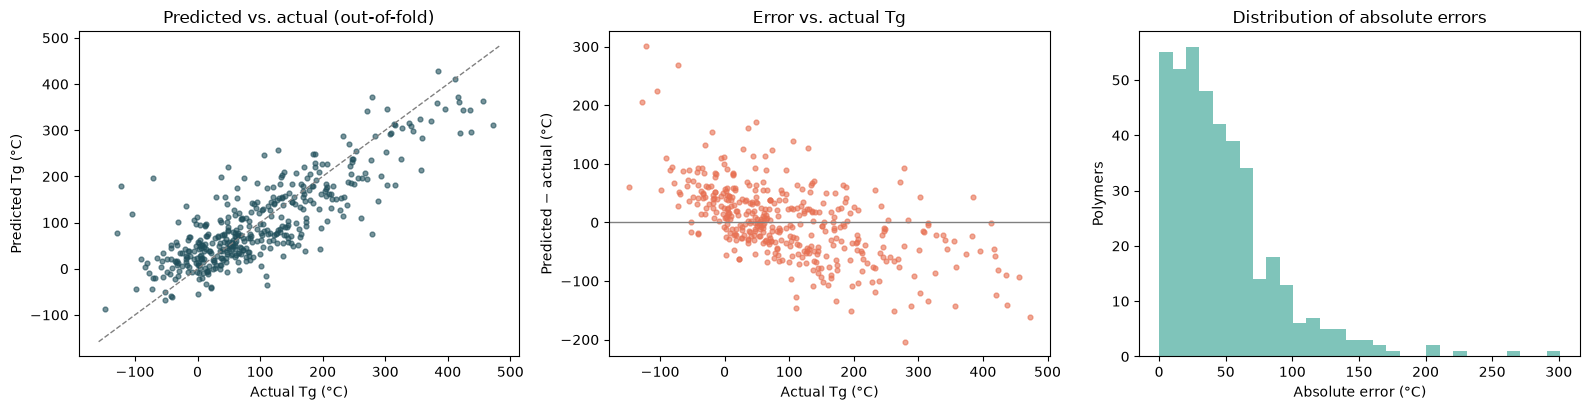

The 10% largest errors make up 29% of the total absolute error


In [4]:

oof["Tg range"] = pd.qcut(oof["Tg"], 5, precision=0)
by_range = oof.groupby("Tg range", observed=True).agg(
    polymers=("Tg", "size"), mean_Tg=("Tg", "mean"), mean_predicted=("predicted", "mean"),
    MAE=("abs_error", "mean"), mean_error=("error", "mean"))
display(by_range.round(1))

slope = np.polyfit(oof["Tg"], oof["predicted"], 1)[0]
print(f"Slope of predicted vs. actual Tg: {slope:.2f} (1 = no shrinkage towards the mean)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
lim = [oof[["Tg", "predicted"]].min().min() - 10, oof[["Tg", "predicted"]].max().max() + 10]
axes[0].scatter(oof["Tg"], oof["predicted"], s=12, alpha=0.6, color="#1f4e5a")
axes[0].plot(lim, lim, color="grey", linestyle="--", linewidth=1)
axes[0].set(xlabel="Actual Tg (°C)", ylabel="Predicted Tg (°C)", title="Predicted vs. actual (out-of-fold)")
axes[1].scatter(oof["Tg"], oof["error"], s=12, alpha=0.6, color="#e76f51")
axes[1].axhline(0, color="grey", linewidth=1)
axes[1].set(xlabel="Actual Tg (°C)", ylabel="Predicted − actual (°C)", title="Error vs. actual Tg")
axes[2].hist(oof["abs_error"], bins=30, color="#7fc4ba")
axes[2].set(xlabel="Absolute error (°C)", ylabel="Polymers", title="Distribution of absolute errors")
plt.tight_layout()
plt.show()

share = oof["abs_error"].sort_values(ascending=False)
top10 = share.head(int(0.1 * len(share))).sum() / share.sum()
print(f"The 10% largest errors make up {100 * top10:.0f}% of the total absolute error")


### 4.2 The largest errors

In [5]:

display(oof.nlargest(15, "abs_error")[["SMILES", "Tg", "predicted", "error"]].round(0))


,SMILES,Tg,predicted,error
row,,,,
2725,*c1cc(*)c(O)c(C=Nc2ccc(F)cc2)c1,-122.0,179.0,301.0
3035,*C(=O)Oc1ccc(OC(=O)c2ccc3c(c2)C(=O)N(c2ccc(N4C(=O)c5ccc(*)cc5C4=O)cc2)C3=O)cc1,-72.0,197.0,269.0
6559,*Oc1cccc(OC(=O)Oc2ccc(OC(*)=O)cc2)c1,-104.0,119.0,223.0
3219,*c1ccc(N(*)CCCCCC)cc1,-129.0,77.0,206.0
5741,*c1ccc(*)n1C(C)C(=O)OC,279.0,76.0,-204.0
4678,*C(=O)Nc1ccc(NC(=O)c2ccc3c(c2)C(=O)N(c2ccc(Oc4ccc(N5C(=O)c6ccc(*)cc6C5=O)cc4...,48.0,220.0,171.0
1712,*Nc1ccc(Cc2ccc(NC(=O)c3cc(NC(=O)C(CC(C)C)N4C(=O)c5ccccc5C4=O)cc(C(*)=O)c3)cc...,37.0,198.0,161.0
3358,*c1ccc(-c2ccc(N3C(=O)c4cc5c(cc4C3=O)C(C(F)(F)F)(C(F)(F)F)c3cc4c(cc3O5)C(=O)N...,472.0,311.0,-161.0
2832,*Oc1ccc(Oc2ccc(Oc3cccc(*)n3)cc2)cc1,-19.0,136.0,155.0



### 4.3 Error by chemical class

Each polymer is assigned to one class by the first matching backbone group
(functional-group descriptors from notebook 04), in this order of priority.


In [6]:

class_rules = [
    ("Polyimide", "ImideBackbone"), ("Polyamide", "AmideBackbone"),
    ("Polyurethane", "UrethaneBackbone"), ("Polycarbonate", "CarbonateBackbone"),
    ("Polysiloxane", "SiloxaneBackbone"), ("Polysulfone", "SulfoneBackbone"),
    ("Polyester", "EsterBackbone"), ("Polyether", "EtherBackbone"),
]


def chemical_class(row):
    for name, column in class_rules:
        if row[column] > 0:
            return name
    if row["BackboneAromaticFraction"] > 0:
        return "Other, aromatic backbone"
    return "Other, aliphatic backbone (e.g. vinyl)"


polymer_class = bplus_df.join(chain_df).apply(chemical_class, axis=1)
oof["class"] = polymer_class.loc[oof.index]

by_class = oof.groupby("class").agg(polymers=("Tg", "size"), mean_Tg=("Tg", "mean"),
                                    Tg_std=("Tg", "std"), MAE=("abs_error", "mean"),
                                    mean_error=("error", "mean"))
display(by_class.sort_values("MAE", ascending=False).round(1))


,polymers,mean_Tg,Tg_std,MAE,mean_error
class,,,,,
Polysiloxane,1,-64.1,NaN,87.1,87.1
Polycarbonate,5,33.4,90.1,77.2,30.3
Polyimide,29,202.8,114.1,61.4,-6.2
"Other, aromatic backbone",83,140.3,136.0,57.1,6.6
"Other, aliphatic backbone (e.g. vinyl)",82,41.9,79.9,46.5,-0.1
Polyamide,80,109.9,93.3,45.2,-6.5
Polyether,29,123.1,129.0,45.1,5.0
Polysulfone,13,174.4,118.9,42.1,-9.3
Polyurethane,19,39.2,54.5,39.7,-2.2



### 4.4 Error vs. similarity to the training polymers

For each polymer, the **nearest-neighbour similarity** is the highest Tanimoto
similarity (Morgan fingerprints) to any polymer in the training part of its fold.
A low value means the model has seen nothing similar.


,polymers,MAE,nearest_neighbour_MAE
similarity,,,
"(-0.001, 0.3]",36,58.2,105.8
"(0.3, 0.5]",179,46.1,72.4
"(0.5, 0.7]",137,51.6,65.4
"(0.7, 1.0]",56,38.3,56.1


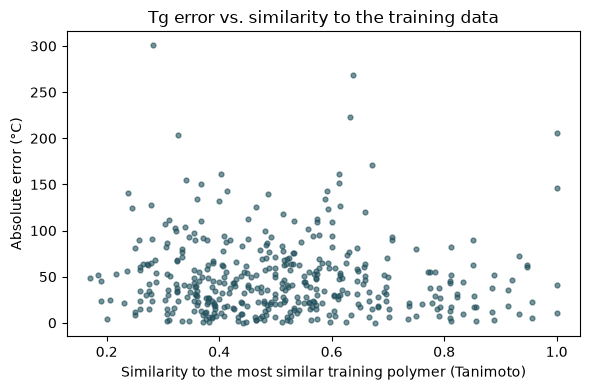

In [7]:

bits = fingerprint_df.to_numpy(dtype=float)


def tanimoto(a, b):
    common = a @ b.T
    return common / (a.sum(axis=1)[:, None] + b.sum(axis=1)[None, :] - common)


nearest = pd.Series(index=oof.index, dtype=float)
nearest_tg = pd.Series(index=oof.index, dtype=float)
for fold in range(N_FOLDS):
    rows = fold_rows["Tg"][fold]
    fit_rows = np.setdiff1d(train_rows["Tg"], rows)
    similarity = tanimoto(bits[rows], bits[fit_rows])
    nearest.loc[rows] = similarity.max(axis=1)
    nearest_tg.loc[rows] = labels[fit_rows[similarity.argmax(axis=1)], TG]

oof["nearest_similarity"] = nearest
oof["nearest_Tg"] = nearest_tg
oof["similarity"] = pd.cut(oof["nearest_similarity"], [0, 0.3, 0.5, 0.7, 1.0], include_lowest=True)
display(oof.groupby("similarity", observed=True).agg(
    polymers=("Tg", "size"), MAE=("abs_error", "mean"),
    nearest_neighbour_MAE=("nearest_Tg", lambda s: np.mean(np.abs(s - oof.loc[s.index, "Tg"])))
).round(1))

plt.figure(figsize=(6, 4))
plt.scatter(oof["nearest_similarity"], oof["abs_error"], s=12, alpha=0.6, color="#1f4e5a")
plt.xlabel("Similarity to the most similar training polymer (Tanimoto)")
plt.ylabel("Absolute error (°C)")
plt.title("Tg error vs. similarity to the training data")
plt.tight_layout()
plt.show()



### 4.5 Are the labels consistent?

Pairs of training polymers with almost identical structure (Tanimoto ≥ 0.9) but very
different Tg point to label noise, or to structural details the descriptors cannot see.


In [8]:

tg_rows = train_rows["Tg"]
tg_smiles = train.loc[tg_rows, "SMILES"]
print(f"Duplicate SMILES among the Tg training polymers: {tg_smiles.duplicated().sum()}")

similarity = tanimoto(bits[tg_rows], bits[tg_rows])
i, j = np.triu_indices(len(tg_rows), k=1)
pairs = pd.DataFrame({"a": tg_rows[i], "b": tg_rows[j], "similarity": similarity[i, j]})
pairs = pairs[pairs["similarity"] >= 0.9].copy()
pairs["Tg_difference"] = np.abs(labels[pairs["a"], TG] - labels[pairs["b"], TG])
print(f"Pairs with similarity ≥ 0.9: {len(pairs)}; "
      f"median Tg difference {pairs['Tg_difference'].median():.0f} °C; "
      f"pairs differing by > 50 °C: {(pairs['Tg_difference'] > 50).sum()}")

examples = pairs.nlargest(8, "Tg_difference")
display(pd.DataFrame({
    "SMILES a": train.loc[examples["a"], "SMILES"].values,
    "Tg a": labels[examples["a"], TG].round(0),
    "SMILES b": train.loc[examples["b"], "SMILES"].values,
    "Tg b": labels[examples["b"], TG].round(0),
    "similarity": examples["similarity"].round(2).values,
}))


Duplicate SMILES among the Tg training polymers: 0
Pairs with similarity ≥ 0.9: 8; median Tg difference 48 °C; pairs differing by > 50 °C: 4


,SMILES a,Tg a,SMILES b,Tg b,similarity
0,*c1ccc(N(*)CCCCCCC)cc1,111.0,*c1ccc(N(*)CCCCCC)cc1,-129.0,1.00
1,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCCNC(=O)c2ccc(C(=O)O*)cc2)cc1,77.0,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCCCCCNC(=O)c2ccc(C(=O)O*)cc2)cc1,-21.0,0.95
2,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCNC(=O)c2ccc(C(=O)O*)cc2)cc1,4.0,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCCNC(=O)c2ccc(C(=O)O*)cc2)cc1,77.0,0.92
3,*CCCCC(=O)NCCCCCCNC(=O)CCCCO*,-56.0,*CCCCCCC(=O)NCCCCCCNC(=O)CCCO*,1.0,0.93
4,*Oc1ccc(Oc2ccc(NC(=O)c3ccc(C(=O)Nc4ccc(*)cc4)cc3)cc2)cc1,204.0,*Oc1ccc(Oc2ccc(C(=O)Nc3ccc(Oc4ccc(-c5ccc(Oc6ccc(NC(=O)c7ccc(*)cc7)cc6)cc5)cc...,165.0,0.91
5,*NNC(=O)CCCCC(=O)NNC(=O)CCCCCCCC(*)=O,101.0,*NNC(=O)CCC(=O)NNC(=O)CCCCCCCCC(*)=O,65.0,0.96
6,*CCCCCCCCCCOC(=O)CCC(=O)O*,2.0,*CCCCCCCCCCCCCCCCCCCCOC(=O)CCC(=O)O*,-33.0,1.00
7,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCNC(=O)c2ccc(C(=O)O*)cc2)cc1,4.0,*CCCCCCCCCCOC(=O)c1ccc(C(=O)NCCCCCCNC(=O)c2ccc(C(=O)O*)cc2)cc1,-21.0,0.92



## 5. Clustering

### 5.1 Chemical families from k-means

k-means groups the polymers by their 73 descriptors (scaled). It uses no labels and is
fitted only on the polymers outside all validation subsets. The number of clusters is
chosen by the silhouette score.


In [9]:

scaler = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
X_cluster = scaler.fit_transform(descriptors_df.loc[clustering_rows])

silhouette = {}
for k in range(3, 13):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
    sample = np.random.default_rng(RANDOM_STATE).choice(len(X_cluster), 3000, replace=False)
    silhouette[k] = silhouette_score(X_cluster[sample], model.labels_[sample])
display(pd.Series(silhouette, name="silhouette").round(3).to_frame().T)

N_CLUSTERS = max(silhouette, key=silhouette.get)
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit(X_cluster)
cluster = pd.Series(kmeans.predict(scaler.transform(descriptors_df)), index=train.index)
print(f"Chosen number of clusters: {N_CLUSTERS}")

oof["cluster"] = cluster.loc[oof.index]
cluster_summary = pd.DataFrame({
    "polymers": cluster.loc[clustering_rows].value_counts(),
    "Tg training polymers": oof["cluster"].value_counts(),
    "main class": oof.groupby("cluster")["class"].agg(lambda s: s.value_counts().index[0]),
    "mean Tg": oof.groupby("cluster")["Tg"].mean(),
    "Tg std": oof.groupby("cluster")["Tg"].std(),
    "MAE (final model)": oof.groupby("cluster")["abs_error"].mean(),
}).sort_index()
display(cluster_summary.round(1))


,3,4,5,6,7,8,9,10,11,12
silhouette,0.133,0.129,0.138,0.137,0.118,0.119,0.122,0.125,0.1,0.109


Chosen number of clusters: 5


,polymers,Tg training polymers,main class,mean Tg,Tg std,MAE (final model)
0,1266,95,"Other, aliphatic backbone (e.g. vinyl)",46.3,81.9,47.9
1,1728,68,Polyimide,208.0,106.7,53.3
2,483,29,"Other, aliphatic backbone (e.g. vinyl)",15.5,63.6,40.9
3,971,95,Polyamide,33.6,47.1,33.6
4,1737,121,"Other, aromatic backbone",149.7,115.8,57.9



### 5.2 Does clustering improve the Tg model?

Tuned XGBoost (73 descriptors + fingerprints) on the same five folds, compared with:

- **+ cluster label:** the cluster number as one-hot features,
- **+ cluster distances:** the distance to every cluster centre as features,
- **one model per cluster:** a separate XGBoost for each cluster with at least
  40 training polymers; the remaining polymers use the global model.


In [10]:

cluster_onehot = pd.get_dummies(cluster, prefix="cluster", dtype=float)
cluster_distance = pd.DataFrame(kmeans.transform(scaler.transform(descriptors_df)),
                                index=train.index).add_prefix("distance_")
variants = {
    "Global model": X_all,
    "+ cluster label": np.hstack([X_all, cluster_onehot.to_numpy()]),
    "+ cluster distances": np.hstack([X_all, cluster_distance.to_numpy()]),
}

cluster_rows = []
for fold in range(N_FOLDS):
    rows = fold_rows["Tg"][fold]
    fit_rows = np.setdiff1d(train_rows["Tg"], rows)
    y_true = labels[rows, TG]
    baseline = np.mean(np.abs(y_true - np.median(labels[fit_rows, TG])))

    predictions = {}
    for name, X in variants.items():
        predictions[name] = create_tg_xgboost().fit(X[fit_rows], labels[fit_rows, TG]).predict(X[rows])

    # One model per cluster where there are enough training polymers
    per_cluster = predictions["Global model"].copy()
    for c in range(N_CLUSTERS):
        fit_c = fit_rows[cluster.loc[fit_rows].to_numpy() == c]
        eval_c = cluster.loc[rows].to_numpy() == c
        if len(fit_c) >= 40 and eval_c.any():
            model = create_tg_xgboost().fit(X_all[fit_c], labels[fit_c, TG])
            per_cluster[eval_c] = model.predict(X_all[rows[eval_c]])
    predictions["One model per cluster"] = per_cluster

    for name, y_pred in predictions.items():
        mae = mean_absolute_error(y_true, y_pred)
        cluster_rows.append({"variant": name, "fold": fold, "MAE": mae,
                             "error_reduction": 100 * (1 - mae / baseline)})

cluster_results = pd.DataFrame(cluster_rows).groupby("variant").agg(
    MAE=("MAE", "mean"), error_reduction=("error_reduction", "mean"),
    error_reduction_std=("error_reduction", "std"))
display(cluster_results.loc[["Global model", "+ cluster label", "+ cluster distances",
                             "One model per cluster"]].round(1))


,MAE,error_reduction,error_reduction_std
variant,,,
Global model,48.2,45.6,2.6
+ cluster label,48.2,45.5,2.6
+ cluster distances,48.3,45.4,2.5
One model per cluster,49.3,44.4,2.6



### 5.3 How well does the model predict an unseen family?

With random folds, most test polymers have relatives in the training data. Here each
cluster is held out completely in turn (group cross-validation), which simulates
predicting Tg for a new family of polymers.


In [11]:

tg_rows = train_rows["Tg"]
groups = cluster.loc[tg_rows].to_numpy()
y = labels[tg_rows, TG]

group_rows = []
for fit_idx, test_idx in GroupKFold(n_splits=len(np.unique(groups))).split(tg_rows, y, groups):
    model = create_tg_xgboost().fit(X_all[tg_rows[fit_idx]], y[fit_idx])
    y_pred = model.predict(X_all[tg_rows[test_idx]])
    baseline = np.mean(np.abs(y[test_idx] - np.median(y[fit_idx])))
    mae = mean_absolute_error(y[test_idx], y_pred)
    group_rows.append({"held-out cluster": groups[test_idx][0], "polymers": len(test_idx),
                       "MAE": mae, "baseline MAE": baseline,
                       "error_reduction": 100 * (1 - mae / baseline)})

group_df = pd.DataFrame(group_rows).set_index("held-out cluster").sort_index()
display(group_df.round(1))
weighted_mae = np.average(group_df["MAE"], weights=group_df["polymers"])
random_mae = cluster_results.loc["Global model", "MAE"]
print(f"MAE with random folds: {random_mae:.1f} °C | MAE for unseen families: {weighted_mae:.1f} °C")


,polymers,MAE,baseline MAE,error_reduction
held-out cluster,,,,
0,95,58.6,77.3,24.2
1,68,71.5,154.1,53.6
2,29,44.9,74.6,39.7
3,95,35.6,80.3,55.6
4,121,69.8,114.7,39.1


MAE with random folds: 48.2 °C | MAE for unseen families: 57.8 °C


## 6. Aromatic backbones with Tg below 0 °C

A Tg below 0 °C is normal for flexible polymers (polyethers, aliphatic polyesters,
siloxanes, acrylates with long side chains). For a polymer whose backbone is mostly
aromatic, it is chemically implausible. These labels are flagged by a simple rule:

- Tg < 0 °C **and** at least half of the backbone atoms are aromatic
  (`BackboneAromaticFraction` ≥ 0.5).

The rule is applied to the Tg training subset only. The flagged polymers are then left
out of **training**, but every polymer, flagged or not, is still **evaluated**, so the score
is not flattered by removing hard cases.

In [12]:

tg_train = train.loc[train_rows["Tg"], ["SMILES", "Tg"]].join(
    chain_df[["BackboneAromaticFraction", "BackboneRotatableFraction", "BackboneRingCount"]])
flagged = tg_train[(tg_train["Tg"] < 0) & (tg_train["BackboneAromaticFraction"] >= 0.5)]
print(f"Flagged: {len(flagged)} of {len(tg_train)} Tg training polymers "
      f"({(tg_train['Tg'] < 0).sum()} have Tg < 0 °C)")
display(flagged.join(oof[["predicted"]]).sort_values("Tg").round(2))


Flagged: 9 of 408 Tg training polymers (68 have Tg < 0 °C)


,SMILES,Tg,BackboneAromaticFraction,BackboneRotatableFraction,BackboneRingCount,predicted
3219,*c1ccc(N(*)CCCCCC)cc1,-128.63,0.80,0.40,1.0,77.06
2725,*c1cc(*)c(O)c(C=Nc2ccc(F)cc2)c1,-121.52,1.00,0.33,1.0,179.37
6559,*Oc1cccc(OC(=O)Oc2ccc(OC(*)=O)cc2)c1,-104.34,0.54,0.62,2.0,119.11
3035,*C(=O)Oc1ccc(OC(=O)c2ccc3c(c2)C(=O)N(c2ccc(N4C(=O)c5ccc(*)cc5C4=O)cc2)C3=O)cc1,-71.68,0.64,0.36,6.0,197.29
3604,*C#Cc1cc(OC(COCCOCCOCCOC)COCCOCCOCCOC)c(C#Cc2cc(OCCOCCOCCOCCC(=O)O[Na])c(*)c...,-43.36,0.67,0.33,2.0,-11.70
2832,*Oc1ccc(Oc2ccc(Oc3cccc(*)n3)cc2)cc1,-19.12,0.79,0.43,3.0,135.65
2024,*C=Cc1ccc(*)n1CCCCCC,-15.04,0.60,0.40,1.0,62.57
2372,*NC(=O)c1cc(C(=O)Nc2nc(*)nc(-c3ccccc3)n2)c(C(=O)OC(=O)Nc2cc(NC(=O)OCCCCCCCC)...,-1.69,0.60,0.40,2.0,97.66
444,*Nc1c(Cl)cc(*)cc1Cl,-0.21,0.80,0.40,1.0,111.39


In [13]:

flagged_rows = flagged.index.to_numpy()

clean_rows = []
for fold in range(N_FOLDS):
    rows = fold_rows["Tg"][fold]
    fit_all = np.setdiff1d(train_rows["Tg"], rows)
    fit_clean = np.setdiff1d(fit_all, flagged_rows)
    y_true = labels[rows, TG]
    baseline = np.mean(np.abs(y_true - np.median(labels[fit_all, TG])))
    is_flagged = np.isin(rows, flagged_rows)

    # Multi-task network: the flagged Tg labels are masked, the other targets stay
    Y_fold = np.full_like(labels, np.nan)
    for t, target in enumerate(target_columns):
        fit_rows = np.setdiff1d(train_rows[target], fold_rows[target][fold])
        Y_fold[fit_rows, t] = labels[fit_rows, t]
    Y_fold[flagged_rows, TG] = np.nan
    has_label = ~np.isnan(Y_fold).all(axis=1)
    predict_network = fit_network(X_network[has_label], Y_fold[has_label], seed=RANDOM_STATE + fold)

    xgboost_clean = create_tg_xgboost().fit(X_all[fit_clean], labels[fit_clean, TG]).predict(X_all[rows])
    predictions = {
        "XGBoost, all labels": oof.loc[rows, "xgboost"].to_numpy(),
        "XGBoost, without flagged": xgboost_clean,
        "Ensemble, all labels": oof.loc[rows, "predicted"].to_numpy(),
        "Ensemble, without flagged": (predict_network(X_network[rows])[:, TG] + xgboost_clean) / 2,
    }
    for name, y_pred in predictions.items():
        errors = np.abs(y_pred - y_true)
        clean_rows.append({"model": name, "fold": fold,
                           "MAE (all polymers)": errors.mean(),
                           "error_reduction": 100 * (1 - errors.mean() / baseline),
                           "MAE (unflagged polymers)": errors[~is_flagged].mean(),
                           "sum of errors on flagged": errors[is_flagged].sum(),
                           "n flagged": is_flagged.sum()})

clean_df = pd.DataFrame(clean_rows)
clean_summary = clean_df.groupby("model").agg(
    MAE_all=("MAE (all polymers)", "mean"), error_reduction=("error_reduction", "mean"),
    error_reduction_std=("error_reduction", "std"),
    MAE_unflagged=("MAE (unflagged polymers)", "mean"))
clean_summary["MAE_flagged"] = (clean_df.groupby("model")["sum of errors on flagged"].sum()
                                / clean_df.groupby("model")["n flagged"].sum())
display(clean_summary.loc[["XGBoost, all labels", "XGBoost, without flagged",
                           "Ensemble, all labels", "Ensemble, without flagged"]].round(1))


,MAE_all,error_reduction,error_reduction_std,MAE_unflagged,MAE_flagged
model,,,,,
"XGBoost, all labels",48.2,45.6,2.6,45.4,170.7
"XGBoost, without flagged",49.4,44.3,1.3,46.7,168.5
"Ensemble, all labels",47.9,45.9,2.3,45.3,163.8
"Ensemble, without flagged",48.2,45.6,2.1,45.6,162.8


## 7. Reducing the shrinkage at the extremes

The model predicts low Tg too high and high Tg too low (slope 0.69, section 4.1).
Four ways to counter this are compared with tuned XGBoost (73 descriptors + fingerprints)
on the same five folds:

- **MAE objective:** XGBoost minimises the absolute error directly instead of the squared error.
- **Extremes weighted:** each training polymer gets the weight 1 + |Tg − median| / std,
  so polymers far from the middle count more.
- **Less regularised:** deeper trees (depth 4 instead of 2) and weaker L2 penalty
  (λ = 1 instead of 7.5), so the model can follow the extremes more closely.
- **Stretched predictions:** a straight line actual ≈ a × predicted + b is fitted on
  inner cross-validation predictions of the training part of each fold (never on the
  evaluated polymers) and used to stretch the predictions.


In [14]:

def fit_xgboost(params, X, y, weights=None):
    model = make_pipeline(SimpleImputer(strategy="median"),
                          XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1))
    return model.fit(X, y, xgbregressor__sample_weight=weights)


def extreme_weights(y):
    return 1 + np.abs(y - np.median(y)) / y.std()


def stretch_line(params, X, y, weights_fn=None):
    # Inner 5-fold predictions on the training part only, then a least-squares line
    inner = np.empty(len(y))
    for fit_idx, test_idx in KFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE).split(X):
        w = weights_fn(y[fit_idx]) if weights_fn else None
        inner[test_idx] = fit_xgboost(params, X[fit_idx], y[fit_idx], w).predict(X[test_idx])
    return np.polyfit(inner, y, 1)


variants = {
    "Current (tuned XGBoost)": (tg_params, None, False),
    "MAE objective": ({**tg_params, "objective": "reg:absoluteerror"}, None, False),
    "Extremes weighted": (tg_params, extreme_weights, False),
    "Less regularised": ({**tg_params, "max_depth": 4, "reg_lambda": 1.0}, None, False),
    "Stretched predictions": (tg_params, None, True),
    "Extremes weighted + stretched": (tg_params, extreme_weights, True),
}

extreme_predictions = {name: pd.Series(index=oof.index, dtype=float) for name in variants}
stretch_lines = []
for fold in range(N_FOLDS):
    rows = fold_rows["Tg"][fold]
    fit_rows = np.setdiff1d(train_rows["Tg"], rows)
    X_fit, y_fit = X_all[fit_rows], labels[fit_rows, TG]

    for name, (params, weights_fn, stretch) in variants.items():
        weights = weights_fn(y_fit) if weights_fn else None
        y_pred = fit_xgboost(params, X_fit, y_fit, weights).predict(X_all[rows])
        if stretch:
            a, b = stretch_line(params, X_fit, y_fit, weights_fn)
            stretch_lines.append({"variant": name, "fold": fold, "a": a, "b": b})
            y_pred = a * y_pred + b
        extreme_predictions[name].loc[rows] = y_pred
    print(f"Fold {fold + 1} done")

display(pd.DataFrame(stretch_lines).round(2))


Fold 1 done


Fold 2 done


Fold 3 done


Fold 4 done


Fold 5 done


,variant,fold,a,b
0,Stretched predictions,0,1.03,-3.77
1,Extremes weighted + stretched,0,0.97,0.53
2,Stretched predictions,1,1.04,-4.19
3,Extremes weighted + stretched,1,0.98,2.19
4,Stretched predictions,2,1.04,-4.34
5,Extremes weighted + stretched,2,0.97,1.98
6,Stretched predictions,3,1.03,-3.56
7,Extremes weighted + stretched,3,0.96,1.19
8,Stretched predictions,4,1.04,-3.78
9,Extremes weighted + stretched,4,0.96,2.13


In [15]:

fold_of = oof["fold"]
summary_rows = []
for name, y_pred in extreme_predictions.items():
    errors = (y_pred - oof["Tg"]).abs()
    per_fold = errors.groupby(fold_of).mean()
    baseline = pd.Series({f: np.mean(np.abs(labels[fold_rows["Tg"][f], TG] - np.median(
        labels[np.setdiff1d(train_rows["Tg"], fold_rows["Tg"][f]), TG]))) for f in range(N_FOLDS)})
    reduction = 100 * (1 - per_fold / baseline)
    row = {"variant": name, "MAE": per_fold.mean(), "error_reduction": reduction.mean(),
           "error_reduction_std": reduction.std(),
           "slope": np.polyfit(oof["Tg"], y_pred, 1)[0]}
    row.update(errors.groupby(oof["Tg range"], observed=True).mean()
               .rename(lambda r: f"MAE {r}").to_dict())
    summary_rows.append(row)

extremes_summary = pd.DataFrame(summary_rows).set_index("variant")
display(extremes_summary.round(1))


,MAE,error_reduction,error_reduction_std,slope,"MAE (-149.0, 5.0]","MAE (5.0, 51.0]","MAE (51.0, 107.0]","MAE (107.0, 185.0]","MAE (185.0, 472.0]"
variant,,,,,,,,,
Current (tuned XGBoost),48.2,45.6,2.6,0.7,60.9,35.0,34.1,48.8,61.8
MAE objective,50.2,43.3,1.9,0.6,64.0,34.8,34.8,50.1,67.3
Extremes weighted,48.5,45.3,3.0,0.7,58.1,37.0,38.6,51.4,57.3
Less regularised,49.4,44.3,3.3,0.7,60.8,38.3,36.5,47.6,63.5
Stretched predictions,48.0,45.8,2.7,0.7,58.5,35.7,35.4,50.2,60.1
Extremes weighted + stretched,48.7,45.0,2.9,0.7,58.5,36.0,37.4,50.5,61.0


#### Findings: why the Tg error is large

**1. The model shrinks towards the middle.** The slope of predicted vs. actual Tg is 0.69.
Polymers with very low Tg (below 5 °C) are predicted on average 57 °C too high; polymers
above 185 °C are predicted 47 °C too low. In the middle (50–110 °C), the MAE is only 34 °C.
Most of the error comes from the extremes.

**2. Some labels look chemically implausible.** The 10% largest errors make up 29% of the
total error, and several of them are probably label problems rather than model problems:

- rigid, fully aromatic structures with Tg below −100 °C (rows 2725, 6559) and an aromatic
  poly(ester imide) with Tg −72 °C (row 3035);
- near-identical pairs with very different Tg: poly(N-hexyl) vs. poly(N-heptyl) aniline-type
  structures, −129 °C vs. +111 °C for one extra CH₂ (rows 3219 / 3099). Of the 8 pairs with
  Tanimoto similarity ≥ 0.9, 4 differ by more than 50 °C.

No model can predict such values from the structure. These labels should be checked by a
chemist before deciding what to do with them.

**3. Polymers without similar training examples are predicted worse.** MAE 58 °C when the most
similar training polymer has a Tanimoto similarity ≤ 0.3, vs. 38 °C when it is > 0.7.
With 408 training polymers, many structures have no close relative: more data would help.

**4. Chemical classes:** the largest errors are for polyimides (61 °C) and other aromatic
backbones (57 °C), which have high and widely spread Tg values; polyesters (38 °C) and
polyurethanes (40 °C) are predicted best.

**5. Clustering does not improve the model.**

| Variant (tuned XGBoost, 5 folds) | MAE (°C) | Error reduction |
|---|---:|---:|
| Global model | 48.2 | 45.6% |
| + cluster label | 48.2 | 45.5% |
| + cluster distances | 48.3 | 45.4% |
| One model per cluster | 49.3 | 44.4% |

- The polymers do not form clear clusters (silhouette score only 0.10–0.14 for 3–12 clusters;
  5 clusters chosen). The tree model already separates the chemical families itself, so the
  cluster label adds no information.
- Separate models per cluster are worse, because each cluster has only 29–121 Tg polymers.
- **Clustering is useful as an analysis tool:** when a whole cluster is held out (a "new family"),
  the MAE rises from 48 °C to 58 °C. The model generalises less well to unfamiliar chemistry,
  which is important to state when the model is used for screening new polymers.

**6. Removing the implausible aromatic labels does not help.** 9 of the 408 Tg training
polymers have Tg < 0 °C with a mostly aromatic backbone (section 6). Training without them
gives MAE 48.2 °C instead of 47.9 °C (ensemble, evaluated on all polymers). The model already
ignores these labels: it predicts them at −12 to +197 °C, so they barely influence the other
predictions. They do, however, add about 160 °C of error each, about 8% of the total Tg error.
The labels are kept for training; they are listed for a chemist's check.

**7. The shrinkage at the extremes cannot be removed by changing the training** (section 7):

| Variant (tuned XGBoost) | MAE | Tg < 5 °C | 51–107 °C | Tg > 185 °C |
|---|---:|---:|---:|---:|
| Current | 48.2 | 60.9 | 34.1 | 61.8 |
| MAE objective | 50.2 | 64.0 | 34.8 | 67.3 |
| Extremes weighted | 48.5 | 58.1 | 38.6 | 57.3 |
| Less regularised | 49.4 | 60.8 | 36.5 | 63.5 |
| Stretched predictions | 48.0 | 58.5 | 35.4 | 60.1 |

- Weighting the extremes moves error from the ends to the middle (−3 to −4 °C at the ends,
  +4 °C in the middle); the total does not improve.
- Stretching barely changes anything: the line fitted on inner predictions has a slope of
  about 1.03, i.e. the predictions are already well calibrated *on average*.
- This shows that the shrinkage is not a bias that can be corrected: when the structure
  does not contain enough information to tell a −30 °C polymer from a +30 °C one, the best
  guess lies closer to the middle. Only more information (more data, better descriptors)
  reduces it.

**Next steps for Tg** (cross-validation only; the validation subsets stay frozen):

1. Review the suspicious labels (chemist's check) and test training without them, while still
   evaluating on all polymers so the score is not flattered.
2. Add external Tg data (minus all validation polymers), since the error clearly depends on
   having similar training examples.
